In [54]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
import matplotlib.pylab as pylab
import numpy as np
%matplotlib inline
from nltk.tokenize import sent_tokenize, word_tokenize
import warnings
warnings.filterwarnings(action = 'ignore')
import gensim
from gensim.models import Word2Vec
import re
import bs4 as bs
import urllib.request
import nltk

In [55]:
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Hp\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Hp\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Hp\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [56]:
## for online word scraping content

url = "https://en.wikipedia.org/wiki/Machine_learning"
try:
    request = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0 (Educational Notebook)'})
    with urllib.request.urlopen(request, timeout=20) as response:
        article = response.read()
    parsed_article = bs.BeautifulSoup(article, 'lxml')
    paragraphs = parsed_article.find_all('p')
    article_text = ' '.join(p.get_text(' ', strip=True) for p in paragraphs)
    print('Downloaded article characters:', len(article_text))
except Exception as exc:
    article_text = ''
    print('Article download unavailable:', exc)
sentences=article_text
#print(article_text)


Downloaded article characters: 62765


In [57]:
# gutenberg link alice-bob story

# scrapped_data = urllib.request.urlopen(
#     urllib.request.Request(
#         "https://www.gutenberg.org/files/11/11-0.txt",
#         headers={"User-Agent": "Mozilla/5.0"}
#     )
# )
# article=scrapped_data.read()
# paresed_article=bs.BeautifulSoup(article,'lxml')
# paragraphs=paresed_article.find_all('p')
# article_text=""
# for p in paragraphs:
#   article_text+=p.text
# sentences=article_text
# print(article_text)

In [58]:
## error occurs in loading file so that we go for manual corpous writing

# sentences="""Alice 23 opened the door and found that it led into a small 90
# passage, not much larger than a rat-hole: she knelt down and
# looked along the passage into the loveliest garden you ever saw.
# How she longed to get out of that dark hall, and wander about
# among those beds of bright flowers and those cool fountains, but
# she could not even get her head through the doorway; `and even if
# my head would go through,' (thought) $poor Alice, `it would be of
# very little use without my shoulders. Oh, how I wish
# I could shut up like a telescope! I think I could, if I only
# know how to begin.' For, you see, so many out-of-the-way things
# had happened lately, that Alice had begun to think that very few
# things indeed were really impossible.
# """

In [59]:
sentences = re.sub('[^A-Za-z0-9]+', ' ', sentences)
sentences = re.sub(r'(?:^| )\w(?:$| )', ' ', sentences).strip()
sentences = sentences.lower()
#print(sentences)

In [60]:
sentences = re.sub('[^A-Za-z]+', ' ', sentences)

sentences = re.sub(r'(?:^| )\w(?:$| )', ' ', sentences).strip()

sentences = sentences.lower()

all_sent=nltk.sent_tokenize(sentences)
all_words=[nltk.word_tokenize(sent) for sent in all_sent]

from nltk.corpus import stopwords
for i in range(len(all_words)):
  all_words[i]=[w for w in all_words[i] if w not in stopwords.words('english')]
data =all_words
data1=data[0]

#print(data)

In [61]:
print(data1[:25])

['machine', 'learning', 'ml', 'field', 'study', 'artificial', 'intelligence', 'concerned', 'development', 'study', 'statistical', 'algorithms', 'learn', 'data', 'generalize', 'unseen', 'data', 'thus', 'perform', 'tasks', 'without', 'explicitly', 'programmed', 'statistics', 'mathematical']


In [62]:
model1 = Word2Vec(
    sentences=data,
    min_count=1,
    vector_size=52,
    window=5,
    sg=0,
    hs=0,
    negative=5,
    workers=1,
    seed=42,
    epochs=100
)

In [63]:
vocabulary = model1.wv.key_to_index
#print(vocabulary)
print("Size:" ,len(vocabulary))

Size: 2083


In [68]:
#wrd='garden'
wrd='supervised'
#wrd=['subset','machine', 'learning','closely','related']
v1 = model1.wv[wrd]

print('Vector length:', len(v1))

similar_words = model1.wv.most_similar(wrd)

for word, score in similar_words:
    print(word, round(float(score), 4))

Vector length: 52
seek 0.9466
unsupervised 0.9428
weakly 0.9145
task 0.894
outperformed 0.8836
unavailability 0.881
typical 0.8806
labelled 0.8745
improvement 0.8688
semi 0.8651


In [65]:
dat = []

for i in range(2, len(data1) - 2):
    context = [data1[i - 2], data1[i - 1], data1[i + 1], data1[i + 2]]
    target = data1[i]
    dat.append((context, target))

print(dat[:5])

if len(dat) > 1:
    print(dat[1][0])
else:
    print("Not enough data to create the second context-target pair.")

[(['machine', 'learning', 'field', 'study'], 'ml'), (['learning', 'ml', 'study', 'artificial'], 'field'), (['ml', 'field', 'artificial', 'intelligence'], 'study'), (['field', 'study', 'intelligence', 'concerned'], 'artificial'), (['study', 'artificial', 'concerned', 'development'], 'intelligence')]
['learning', 'ml', 'study', 'artificial']


In [66]:
i = 3
print('Context:', dat[i][0], '\nTarget:', dat[i][1])
print('Predictions:', model1.predict_output_word(dat[i][0], topn=10))

Context: ['field', 'study', 'intelligence', 'concerned'] 
Target: artificial
Predictions: [('field', np.float32(0.0888789)), ('intelligence', np.float32(0.056981616)), ('study', np.float32(0.018795285)), ('artificial', np.float32(0.012912301)), ('ai', np.float32(0.010091657)), ('early', np.float32(0.008170115)), ('hallucination', np.float32(0.0075061535)), ('ml', np.float32(0.00724251)), ('ethics', np.float32(0.0071792416)), ('studied', np.float32(0.006634376))]


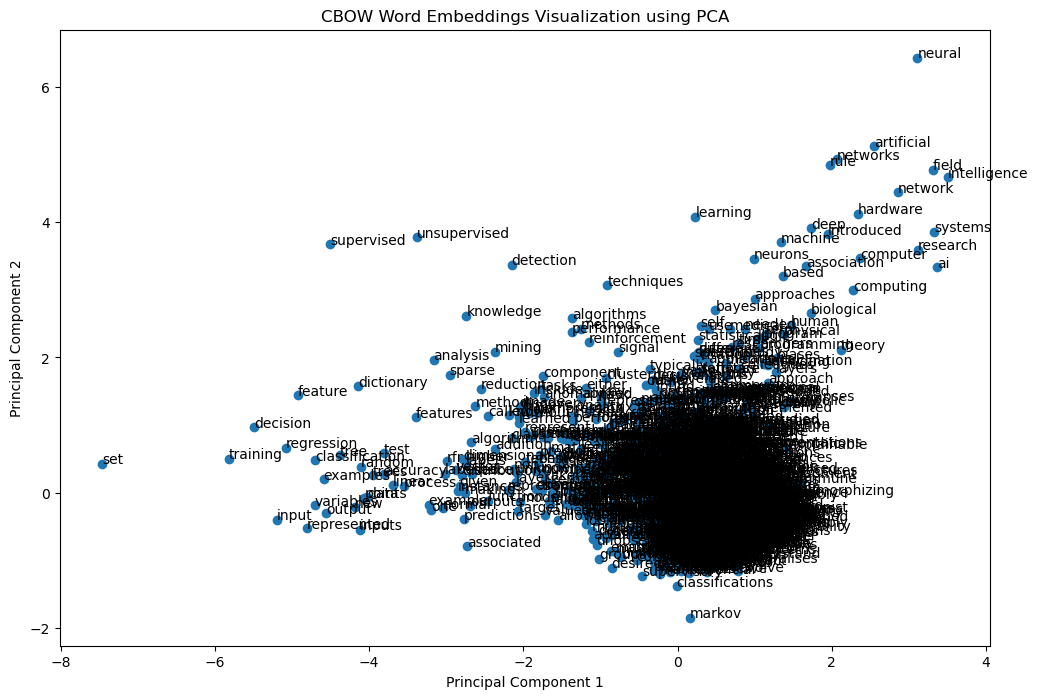

In [67]:
from sklearn.decomposition import PCA
from matplotlib import pyplot

words = model1.wv.index_to_key
X = model1.wv[words]

pca = PCA(n_components=2)
result = pca.fit_transform(X)

pyplot.figure(figsize=(12, 8))
pyplot.scatter(result[:, 0], result[:, 1])

for i, word in enumerate(words):
    pyplot.annotate(
        word,
        xy=(result[i, 0], result[i, 1])
    )

pyplot.xlabel("Principal Component 1")
pyplot.ylabel("Principal Component 2")
pyplot.title("CBOW Word Embeddings Visualization using PCA")
pyplot.show()